# Imports

In [1]:
# ---- Device: must run before anything imports jax ----
from devices import use_device
use_device("auto")      # "auto" | "gpu" | "cpu"  (restart the kernel to switch)

import os
# os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false") # If sharing GPU with other processes
os.environ.setdefault("XLA_PYTHON_CLIENT_MEM_FRACTION", "0.2") # If not set, JAX automatically grabs 75% of the GPU's total memory, which can be excessive
# os.environ["XLA_FLAGS"] = (os.environ.get("XLA_FLAGS", "") + " --xla_gpu_deterministic_ops=true").strip() #force deterministic computation on GPU
import jax, numpyro
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print(jax.default_backend())   # 'gpu' or 'cpu': where JAX runs things by default
print(jax.devices())           # e.g. [CudaDevice(id=0)] for the GPU, or 8 CpuDevices
print("local device count:", jax.local_device_count())

import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value

from likelihood import (
    FD_gaussianlikelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
    wraparound_ratio_posthoc,
)
from model import (
    setup_model,
    make_orthogonal_poly_log_sed,
)
from data import (
    prepare_burst,
)
from run import (
    set_priors,
    run_fit,
    posthoc_samples,
)
from results import (
    save_run,
    to_idata,
)

from plotting import (
    plot_burst_TD, 
    plot_burst_FD,
    model_from_draw,
    plot_fit_TD,
    plot_fit_FD,
    plot_noise_window,
    to_time_domain,
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import arviz as az
import arviz_plots as azp
az.rcParams["plot.max_subplots"] = 300

import random

FRBayes: running on the GPU


/arc/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX: 0.11.2
gpu
[CudaDevice(id=0)]
local device count: 1


# Setup

820 good channels -> 51 blocks of 16 (4 dropped); block span median 6.641 MHz, max 36.719 MHz
noise estimated from 65 of 329 time bins (first 20% of the segment)
Fourier truncation: keeping 19 of 165 bins (up to 5.6 kHz of 48.7 kHz)
weighted mean frequency 457.9 MHz, reference frequency 451.4 MHz
burst data shape = (51, 19)
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


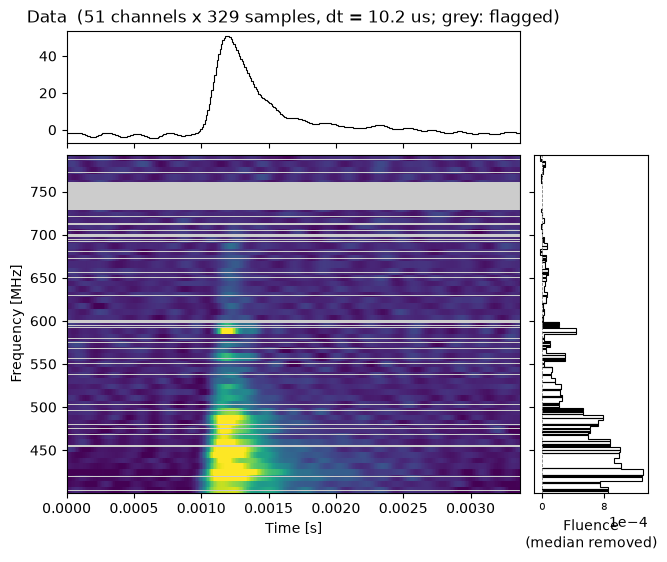

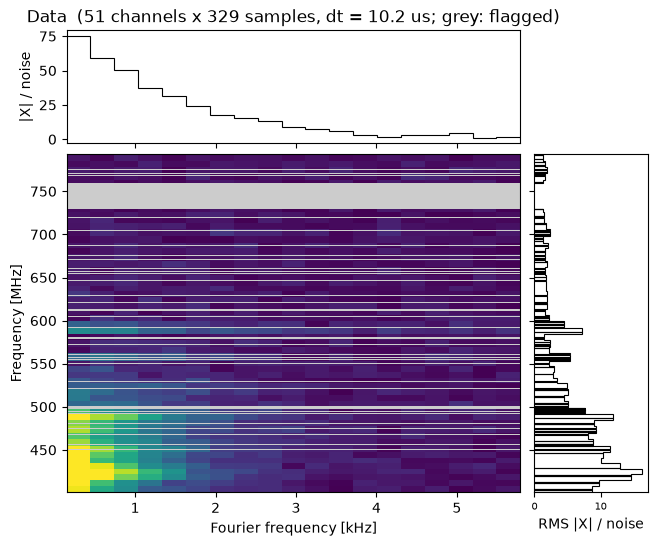

In [12]:
from pathlib import Path

PROJECT  = Path("/arc/home/hsiegel/FRBayes")

# event_id = "22310619_BB" #Multi-pulse, 3 pulses
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# "22310619_BB"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "27687783_BB" #Multi-pulse, many
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=64,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "23438043_BB" # Single-pulse, Narrow SED with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

event_id = "22154974_BB" # Single-pulse, Broadband with scatter
data_path = PROJECT / "data" / f"event_{event_id}.npz"
burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=8,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

print("burst data shape =",burst.data_fd.shape)
plot_burst_TD(burst);                                          # data, in time
plot_burst_FD(burst);                                          # data, in Fourier space

# Run

In [3]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

# n_pulses = 5
# num_chains = 64
n_pulses = 3
num_chains = 64


target_accept_prob = 0.8
seed = 1
num_warmup = 500
num_samples = 200
progress_bar = True
repulsion_dict = {}
# repulsion_dict={"tau_scale":1, "x_min":1}


priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, shrink_sigma_npulses=True)
# priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, delta=dist.Uniform(-5.0, -3.0))
# priors = set_priors(burst, single_pulse_fn, n_pulses, s_opt=100.0, gamma_range=(-10.0, 30.0), beta_range=(-10.0, 30.0))


extend_duration = False # Padding against wraparound: off by default. Turn on when a pulse reaches the window edge.
# fit_fn = single_pulse_fn.extend_model_duration(burst, priors) if extend_duration else single_pulse_fn
fit_fn = single_pulse_fn.extend_model_duration(factor=2) if extend_duration else single_pulse_fn

mcmc = run_fit(burst, fit_fn, priors, FD_gaussianlikelihood, seed=seed,
               num_chains=num_chains, n_pulses=n_pulses, target_accept_prob=target_accept_prob,
               num_warmup=num_warmup, num_samples=num_samples, progress_bar=progress_bar,
               repulsion=repulsion_dict)#, shared_params=("DM", "tau_ref", "delta"))
samples = mcmc.get_samples()

mcmc_data = to_idata(mcmc, log_likelihood={}, posterior_predictive={})
# idata = save_run(None, mcmc, burst, priors, data_path,
#                  single_pulse_fn=fit_fn, extra_samples=extra, event_id=event_id)


KeyboardInterrupt


KeyboardInterrupt



In [47]:
div = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["diverging"]).astype(bool)   # (chain, draw)
print("divergences per chain:", div.sum(axis=1))
# s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
# snr_on = 3.0                                                       # whatever you used
# checks = {
#     "closest-pair x":         s["toa_separation"].min(axis=-1),
#     "smallest A_snr":         s["A_snr"].min(axis=-1),
#     "pulse near snr_on (frac)": (np.abs(s["A_snr"] - snr_on) < 1.0).any(axis=-1).astype(float),
# }
# for name, v in checks.items():
#     print(f"{name:25s} divergent: {np.median(v[div]) if 'frac' not in name else v[div].mean():.2f}   "
#           f"others: {np.median(v[~div]) if 'frac' not in name else v[~div].mean():.2f}")

divergences per chain: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0 22  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  4  0  0 68  0  0  0  0  0  0  0  2]


In [48]:
steps = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["num_steps"])     # (chain, draw), after warmup
depth = np.ceil(np.log2(steps + 1)).astype(int)
max_depth = 10                                                                    # whatever the run used
for c in range(steps.shape[0]):
    print(f"chain {c}: median depth {np.median(depth[c]):.0f}   max {depth[c].max()}   "
          f"hit the limit {np.mean(steps[c] >= 2 ** max_depth - 1):.0%}   mean steps {steps[c].mean():.0f}")

chain 0: median depth 4   max 5   hit the limit 0%   mean steps 16
chain 1: median depth 4   max 6   hit the limit 0%   mean steps 20
chain 2: median depth 5   max 7   hit the limit 0%   mean steps 27
chain 3: median depth 4   max 5   hit the limit 0%   mean steps 16
chain 4: median depth 5   max 5   hit the limit 0%   mean steps 28
chain 5: median depth 8   max 8   hit the limit 0%   mean steps 255
chain 6: median depth 4   max 6   hit the limit 0%   mean steps 21
chain 7: median depth 5   max 7   hit the limit 0%   mean steps 32
chain 8: median depth 4   max 6   hit the limit 0%   mean steps 18
chain 9: median depth 4   max 5   hit the limit 0%   mean steps 17
chain 10: median depth 4   max 6   hit the limit 0%   mean steps 18
chain 11: median depth 7   max 8   hit the limit 0%   mean steps 161
chain 12: median depth 5   max 6   hit the limit 0%   mean steps 31
chain 13: median depth 4   max 5   hit the limit 0%   mean steps 15
chain 14: median depth 4   max 8   hit the limit 0%   me

In [49]:
ns = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["num_steps"])
print("leapfrogs per iteration, median per chain:", np.median(ns, axis=1), "  max:", ns.max())
print("step size per chain:", np.asarray(mcmc.last_state.adapt_state.step_size))

leapfrogs per iteration, median per chain: [ 15.  15.  31.  15.  31. 255.  15.  31.  15.  15.  15. 127.  31.  15.
  15.  15.  15.  15.  15.  15.  15. 255.  31.  15.  15.  47.  15.  15.
  15.  63. 255.  15.  15.  15.  15.  15.  63.  15.  15.  15. 255.  15.
  63.  15.  15. 127. 255.  15.  15.  15.  31.  15.  31.  15.  15.  15.
  15.  15.  79.  15.  31.  63.  15.  63.]   max: 255
step size per chain: [0.21772468 0.21103373 0.17535503 0.22985552 0.14274131 0.0057984
 0.20705526 0.1214463  0.19964516 0.21970049 0.22480103 0.02346857
 0.1252635  0.22731578 0.20786381 0.19717889 0.23372681 0.22806123
 0.21681392 0.21588218 0.21886693 0.01145272 0.1803909  0.20694268
 0.18839999 0.08070733 0.21348068 0.21747221 0.21211357 0.07381866
 0.01395402 0.19235818 0.19725136 0.20506944 0.22641414 0.2008275
 0.04789921 0.19548374 0.21689191 0.2229549  0.00546921 0.27797976
 0.08016758 0.23192245 0.20500915 0.02530872 0.01700997 0.21251564
 0.22944221 0.20620213 0.18141973 0.20899315 0.16728012 0.2081430

In [50]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.000,0.000,0.000,0.000,89.470,110.013,2.249,0.000,0.000
A[1],0.000,0.000,0.000,0.000,85.278,115.015,2.175,0.000,0.000
A[2],0.000,0.000,0.000,0.000,88.519,119.229,2.029,0.000,0.000
A_snr[0],39.851,23.533,1.321,60.474,83.496,82.651,2.240,2.880,1.215
A_snr[1],38.597,20.070,5.113,60.018,77.587,131.814,2.684,2.455,1.297
A_snr[2],29.467,21.913,5.312,59.757,82.929,136.541,2.271,2.681,0.697
DM[0],-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001
DM[1],-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001
DM[2],-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001
DM_shared,-0.004,0.002,-0.006,-0.002,253.215,350.116,1.170,0.000,0.001


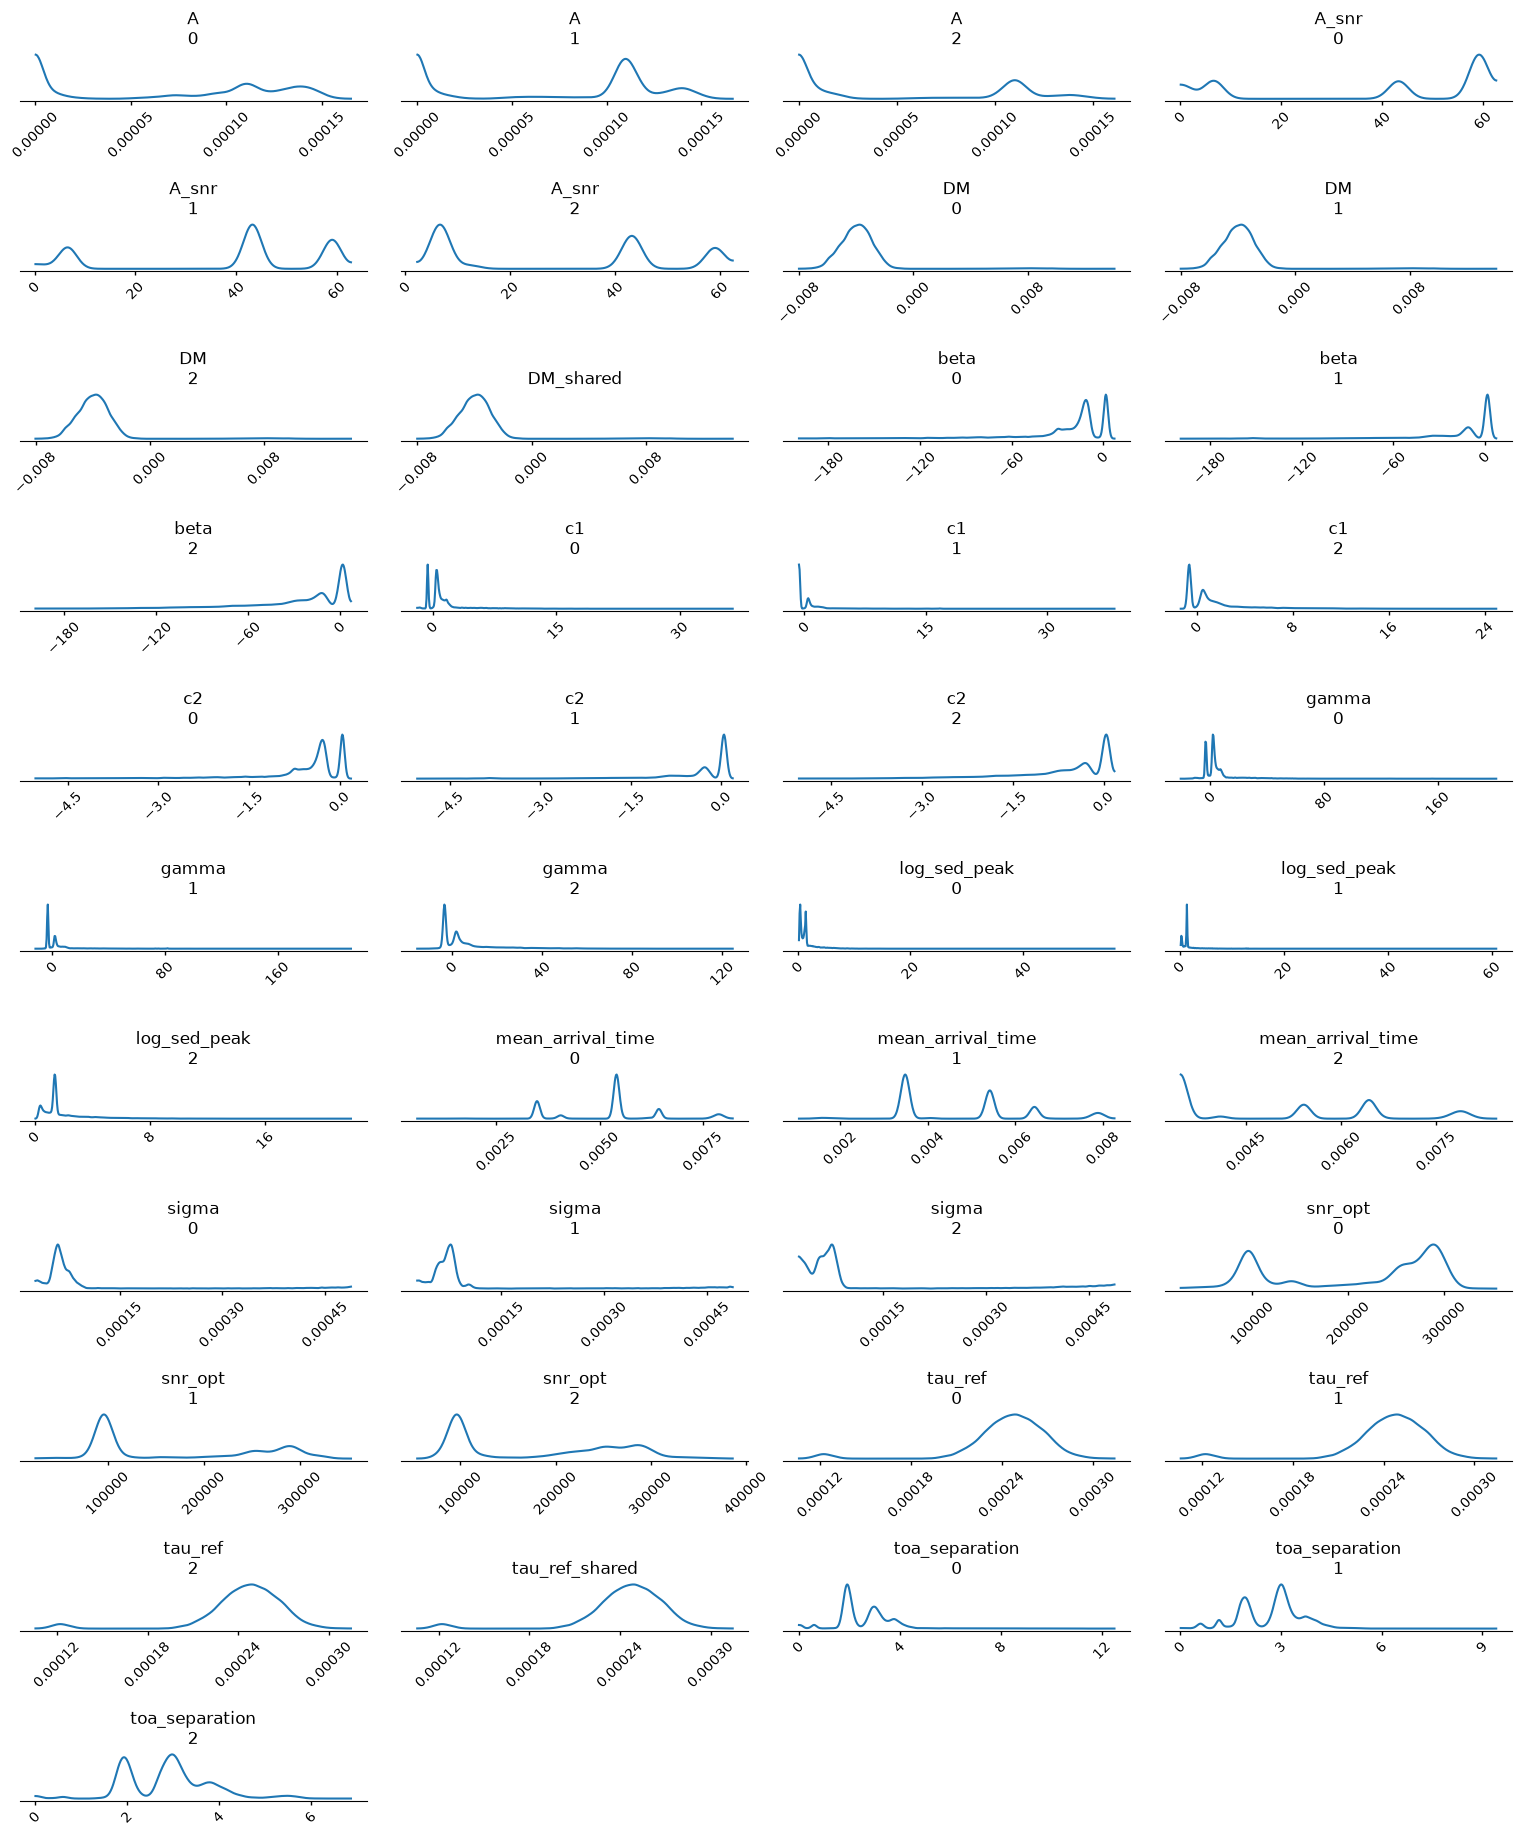

In [51]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw() 

In [52]:
# import warnings

# warnings.filterwarnings(
#     "ignore",
#     message="Explicitly requested dtype.*is not available",
#     category=UserWarning,
# )

# azp.plot_trace(mcmc_data)

# # 2. Clean up x-axis tick clutter across all generated subplots
# for ax in plt.gcf().axes:
#     ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
#     ax.tick_params(axis="x", rotation=45)

# plt.tight_layout()
# plt.show()

In [53]:
pe = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["potential_energy"])
s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
active = s["A_snr"] > 3.0
for c in np.argsort(pe.mean(axis=1)):                      # best (lowest -log post) first
    t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)
    print(f"chain {c}: -log post {pe[c].mean():9.1f} ± {pe[c].std():4.1f}   "
          f"active {active[c].sum(-1).mean():.1f}   t [ms] {np.round(np.sort(t) * 1e3, 2)}   "
          f"A_snr {np.round(np.median(s['A_snr'][c], axis=0), 1)}")

chain 41: -log post    3734.4 ±  2.5   active 3.0   t [ms] [3.52 4.09 5.46]   A_snr [43.3 58.5 12.3]
chain 39: -log post    3734.7 ±  2.6   active 3.0   t [ms] [3.52 4.09 5.46]   A_snr [43.3 58.6 12.5]
chain 45: -log post    3752.9 ±  2.6   active 3.0   t [ms] [3.48 5.41 6.44]   A_snr [59.1 42.9  6.9]
chain 7: -log post    3753.3 ±  3.2   active 3.0   t [ms] [3.48 5.41 6.44]   A_snr [59.1 43.1  6.7]
chain 28: -log post    3753.4 ±  2.9   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [ 6.8 42.9 59.1]
chain 54: -log post    3753.5 ±  2.7   active 3.0   t [ms] [3.48 5.41 6.44]   A_snr [ 6.9 59.1 43. ]
chain 6: -log post    3753.5 ±  2.8   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [ 6.8 42.9 59. ]
chain 58: -log post    3753.5 ±  2.9   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [59.  43.1  6.9]
chain 19: -log post    3753.5 ±  3.0   active 3.0   t [ms] [3.48 5.41 6.43]   A_snr [59.   6.8 42.8]
chain 35: -log post    3753.5 ±  3.0   active 3.0   t [ms] [3.49 5.41 6.44]   A_snr [59.   6.

/tmp/ipykernel_19318/2849936320.py:5: RuntimeWarning: All-NaN slice encountered
  t = np.nanmedian(np.where(active[c], s["mean_arrival_time"][c], np.nan), axis=0)


In [54]:
key = jax.random.PRNGKey(7)

In [64]:
samples = mcmc.get_samples()

mcmc_data = to_idata(mcmc, log_likelihood={}, posterior_predictive={})


sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


draw 11057 (chain 55)
chain 55, draw 11057:  A_snr [58.8  6.2 41.9]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


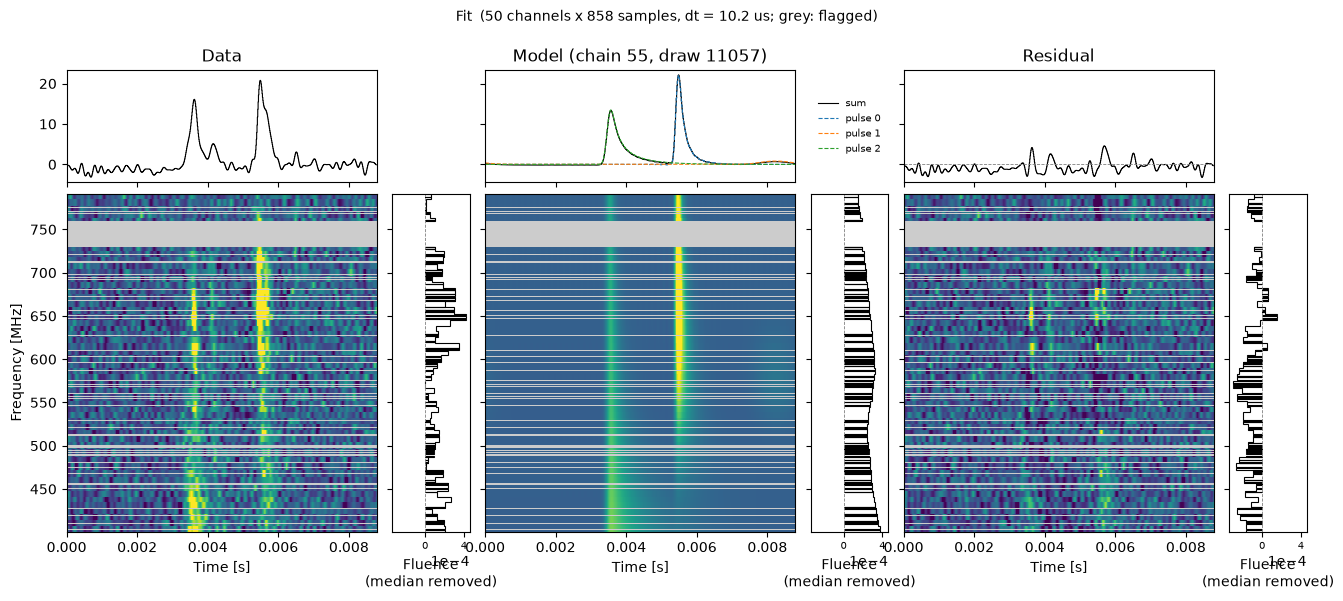

whitened residual sd: 1.182  (expect 1)


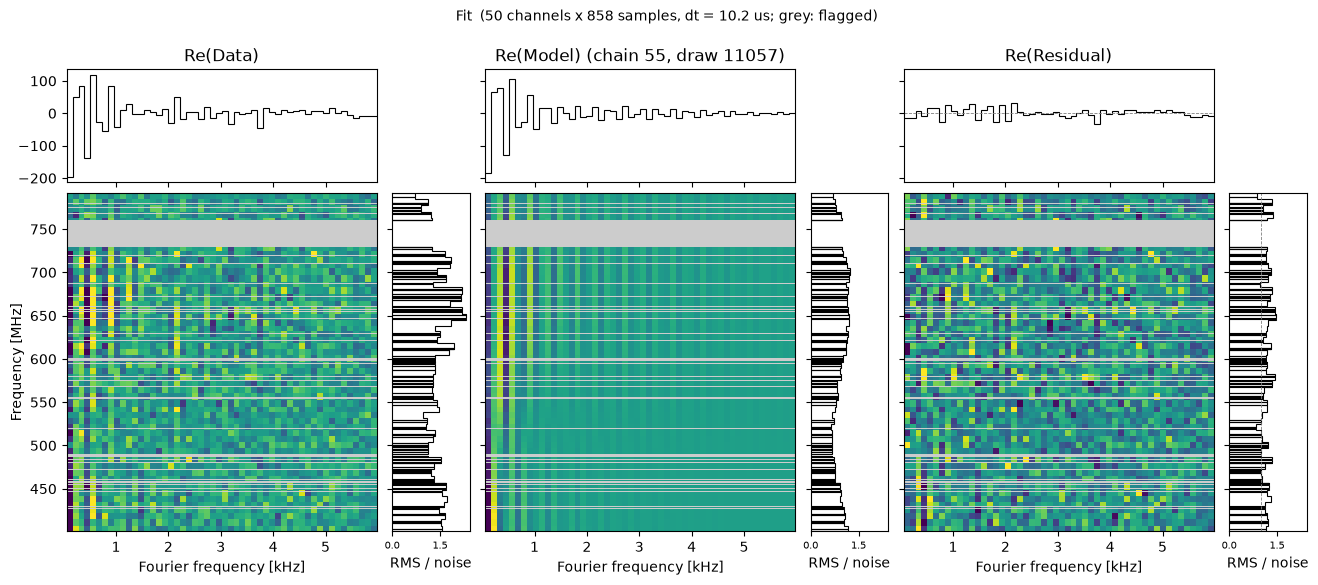

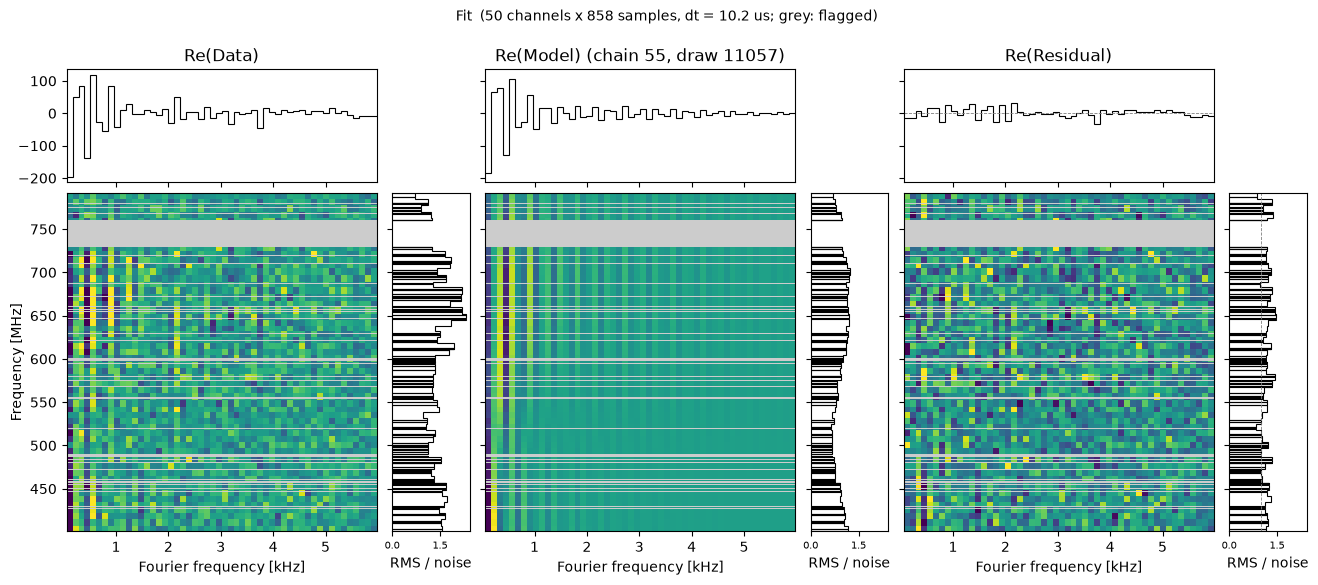

In [67]:
chain = 55                     # the chain to draw from
n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains
draw_idx = chain * n_per_chain + int(np.random.default_rng().integers(n_per_chain))
print(f"draw {draw_idx} (chain {chain})")

print(f"chain {chain}, draw {draw_idx}:  A_snr", np.round(np.asarray(samples["A_snr"][draw_idx]).reshape(-1), 1))

M_FD, M_FD_pulses = model_from_draw(fit_fn, samples, draw_idx)
plot_fit_TD(burst, M_FD, M_FD_pulses, title_model=f"Model (chain {chain}, draw {draw_idx})")
plot_fit_FD(burst, M_FD, title_model=f"Re(Model) (chain {chain}, draw {draw_idx})")

draw 1169 (chain 5)
chain 5, draw 1169:  A_snr [59.4 43.6  6.4]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


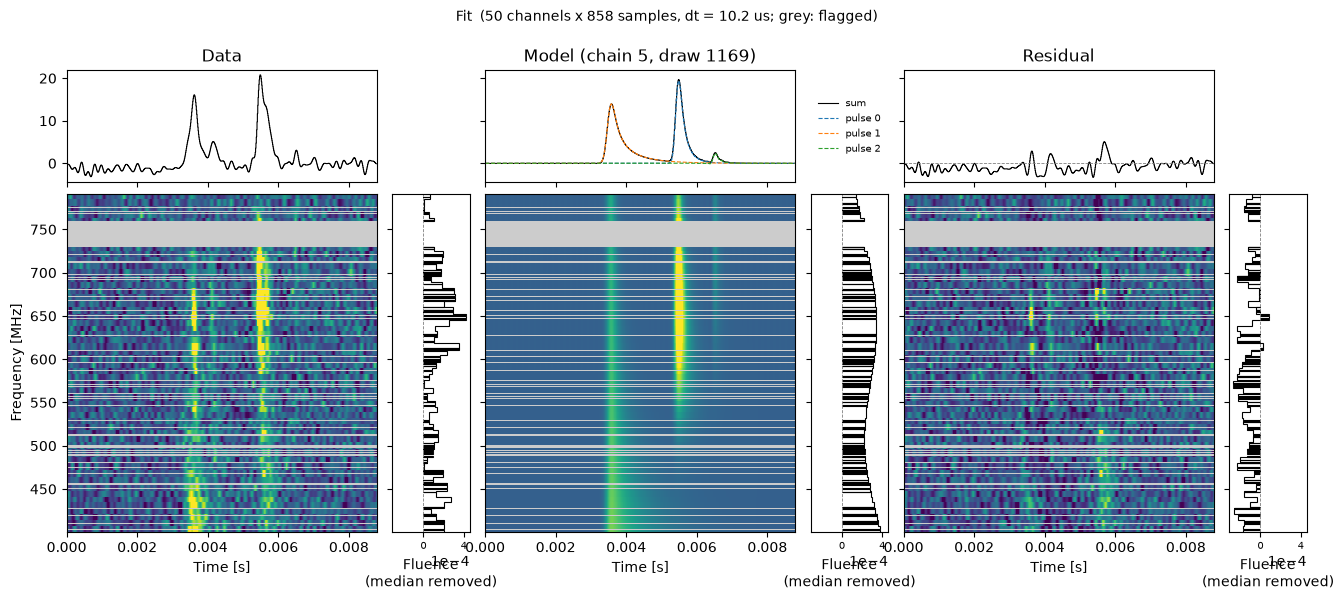

whitened residual sd: 1.190  (expect 1)


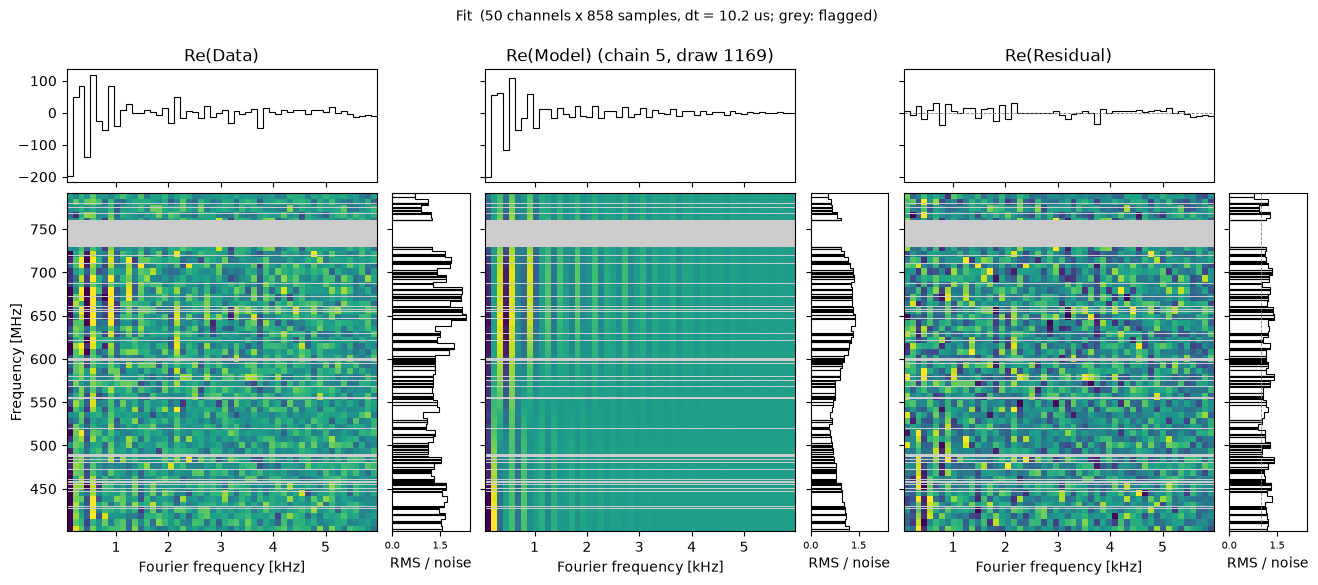

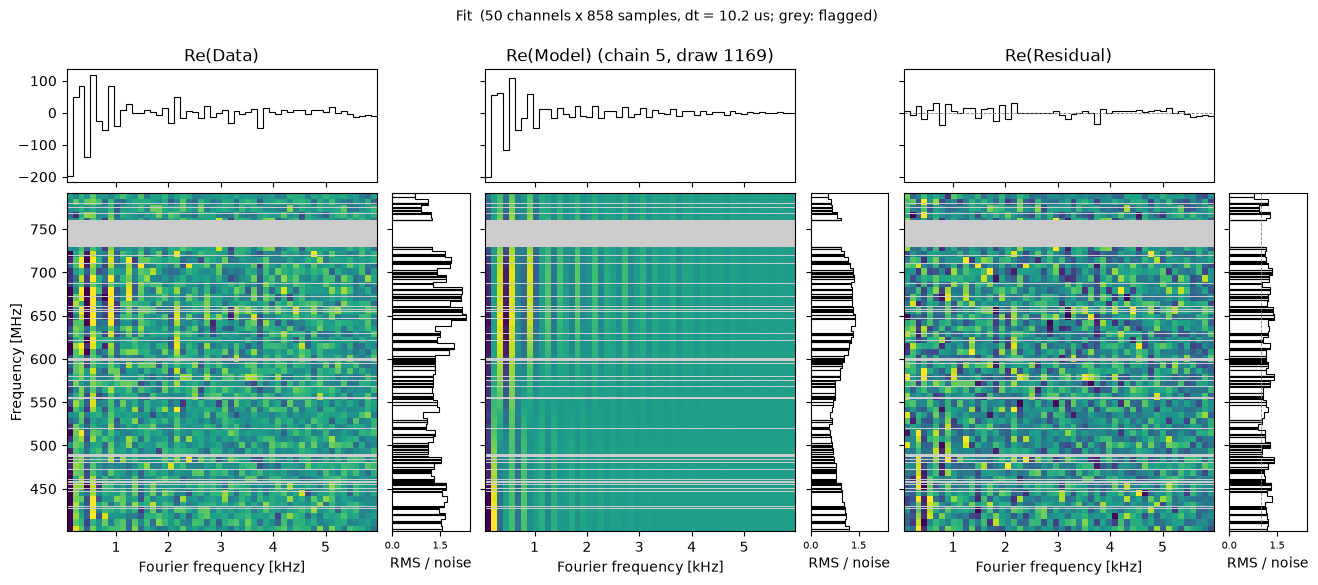

In [57]:
chain = 5                       # the chain to draw from
n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains
draw_idx = chain * n_per_chain + int(np.random.default_rng().integers(n_per_chain))
print(f"draw {draw_idx} (chain {chain})")

print(f"chain {chain}, draw {draw_idx}:  A_snr", np.round(np.asarray(samples["A_snr"][draw_idx]).reshape(-1), 1))

M_FD, M_FD_pulses = model_from_draw(fit_fn, samples, draw_idx)
plot_fit_TD(burst, M_FD, M_FD_pulses, title_model=f"Model (chain {chain}, draw {draw_idx})")
plot_fit_FD(burst, M_FD, title_model=f"Re(Model) (chain {chain}, draw {draw_idx})")

noise window: first 796 of 3983 samples (to 8.15 ms)
  profile mean over the last third of the window: +8.22 standard errors (emission leaking in shows as clearly positive)
  profile sd in the window: 1.06   in the last 20% of the segment: 1.17   (expect 1)


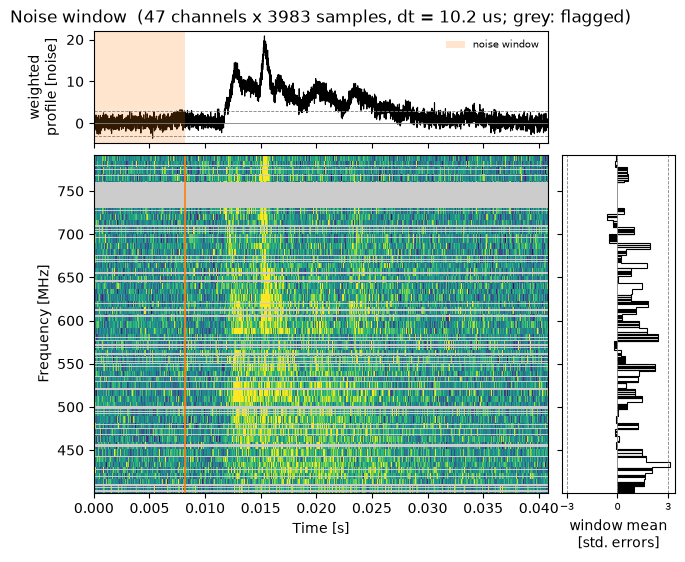

In [7]:
fig = plot_noise_window(burst)

In [59]:
# from postprocess import order_pulses
# samples = order_pulses(mcmc.get_samples(group_by_chain=True))   # or mcmc.get_samples()

In [60]:
# samples

In [61]:
# chain = 12                                                           # the chain to test
# n_per_chain = len(samples["mean_arrival_time"]) // mcmc.num_chains
# draw_idx = chain * n_per_chain + int(np.random.default_rng().integers(n_per_chain))
# M_FD, _ = model_from_draw(fit_fn, samples, draw_idx)
# print(f"chain {chain}, draw {draw_idx}")

R = np.asarray(burst.data_fd) - np.asarray(M_FD)
r = np.asarray(to_time_domain(burst, jnp.asarray(R))) / np.asarray(burst.sigma_noise_td).reshape(-1, 1)
w = np.asarray(burst.channel_weights)
prof = np.tensordot(np.sqrt(w), r, axes=(0, 0))                     # channel-weighted residual profile
prof /= prof[: burst.n_noise_bins].std()                             # unit variance off-pulse, cancelling noise-level errors

K = 20                                                               # window, a few pulse widths in samples
excess = np.convolve(prof ** 2 - 1.0, np.ones(K), mode="valid")      # SNR^2 of residual structure per window
i = int(np.argmax(excess))
print(f"residual SNR {np.sqrt(max(excess[i], 0)):.1f} in the window starting {burst.times[i] * 1e3:.2f} ms  (threshold 10)")

residual SNR 31.1 in the window starting 5.61 ms  (threshold 10)


In [62]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import arviz_plots as azp
from arviz_base import from_dict

# 1. pool within modes, stack between modes
samples = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}   # (chains, draws, ...)
log_lik = pointwise_log_lik(burst, single_pulse_fn, samples, thin=1)
posterior, info = combine_chains(samples, log_lik)        # prints the modes, their weights and draws
print("draws per chain:", dict(enumerate(np.bincount(info["chain"], minlength=len(log_lik)))))

# 2. marginals of the combined posterior
post = {}
for k in ("mean_arrival_time", "sigma", "tau_ref", "DM", "A_snr", "gamma", "beta", "c1", "c2"):
    if k not in posterior:
        continue
    v = np.asarray(posterior[k])
    if v.ndim == 2 and np.allclose(v, v[:, :1]):           # shared parameter, stored once per pulse
        v = v[:, 0]
    post[k] = v[None]                                        # chain axis of length 1
azp.plot_dist(from_dict({"posterior": post}), stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
    for collection in list(ax.collections):
        collection.remove()
plt.tight_layout()
plt.subplots_adjust(wspace=0.1, hspace=2.5)
plt.draw()

ValueError: mode_weights='peak' needs potential_energy: mcmc.get_extra_fields(group_by_chain=True)['potential_energy'].

In [ ]:
import numpy as np
from postprocess import excess_power_search
from plotting import model_from_draw

epsilon, n_test = 0.2, 10
rng = np.random.default_rng(0)
for d in rng.choice(len(posterior["mean_arrival_time"]), n_test, replace=False):
    M_FD, M_FD_pulses = model_from_draw(single_pulse_fn, posterior, d)
    ep = excess_power_search(burst, np.asarray(M_FD), epsilon=epsilon, verbose=False)
    t = ep["tiles"][0]
    print(f"draw {d}: {'ADD' if ep['add_pulse'] else 'stop'}  p={ep['p']:.2g}  "
          f"unexplained SNR {t['snr_unexplained']:.1f} at {t['t_range'][0]*1e3:.1f}-{t['t_range'][1]*1e3:.1f} ms, "
          f"{t['channel_range'][0]:.0f}-{t['channel_range'][1]:.0f} MHz")

In [ ]:
import importlib, postprocess, plotting
importlib.reload(postprocess); importlib.reload(plotting)
from postprocess import excess_power_search
from plotting import model_from_draw, plot_residual_tiles

d = 0                                                         # stacked draw to test
M_FD, M_FD_pulses = model_from_draw(single_pulse_fn, posterior, d)
ep = excess_power_search(burst, np.asarray(M_FD), epsilon=0.2)
plot_residual_tiles(burst, M_FD, ep)

# 1 vs n pulse comparisons

In [3]:
# import importlib, postprocess, plotting
# importlib.reload(postprocess); importlib.reload(plotting)
# from postprocess import excess_power_search
# from plotting import plot_residual_tiles

# ep = excess_power_search(burst, fits[2]["M"])
# plot_residual_tiles(burst, fits[2]["M"], ep)

In [4]:
# for i, t in enumerate(ep["tiles"], 1):
#     print(i, np.round(np.array(t["t_range"]) * 1e3, 2), t["channel_range"],
#           "Fourier band (kHz):", np.round(np.array(t["fourier_band"]) / 1e3, 1),
#           "resolution:", t["resolution"], "cells:", t["n_cells"], "SNR:", round(t["snr_unexplained"], 1))

prior being set with bounds:
sigma_min = 2.8220349260529353e-05 
sigma_max = 0.0005614933299208739 
tau_ref_min = 0.0 
tau_ref_max = 0.0010824326633166927
prior being set with bounds:
c1_min = -4.4036655 
c1_max = 20.124584 
c2_min = -3.1836107 
c2_max = 0.15918054
minimum box width: 5 channels;  delta ELPD threshold: 32.0
prior being set with bounds:
sigma_min = 2.8220349260529353e-05 
sigma_max = 0.0005614933299208739 
tau_ref_min = 0.0 
tau_ref_max = 0.0010824326633166927
prior being set with bounds:
c1_min = -4.4036655 
c1_max = 20.124584 
c2_min = -3.1836107 
c2_max = 0.15918054
mean_arrival_time: Uniform(low=0, high=0.00335872)
DM: Uniform(low=-0.0898636, high=0.0898636)
sigma: LogUniform(low=2.82203e-05, high=0.000561493)
tau_ref: Uniform(low=0, high=0.00108243)
c1: Uniform(low=-4.40367, high=20.1246)
c2: Uniform(low=-3.18361, high=0.159181)
A_snr: HalfNormal(scale=100)
run_fit seed: 2
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampli

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [02:07<00:00,  5.51it/s]


group_chains: 64 chains -> 4 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [28]
  mode 1: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63], largest R-hat within 1.098
  mode 2: chains [15]
  mode 3: chains [52]
  modes weighted by peak posterior:
  mode 0: peak log post -0.1, mean log-lik +0.0, weight 0.470 (stacking would give 0.760), 200 draws from 1 chain(s)
  mode 1: peak log post +0.0, mean log-lik -0.4, weight 0.530 (stacking would give 0.000), 225 draws from 61 chain(s)
  mode 2: peak log post -181.7, mean log-lik -176.7, weight 0.000 (stacking would give 0.208), 0 draws from 1 chain(s)
  mode 3: peak log post -1377.8, mean log-lik -3257.6, weight 0.000 (stacking would give 0.033), 0 draws from 1 chain(s)
combine_chains: 425 draws in all
Residual test (tolerating 20% mode

  0%|          | 0/700 [00:00<?, ?it/s]

sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


sample: 100%|██████████| 700/700 [03:02<00:00,  3.83it/s]


group_chains: 64 chains -> 3 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 4, 5, 8, 10, 11, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23, 25, 26, 27, 28, 29, 32, 34, 35, 36, 38, 39, 40, 43, 45, 46, 50, 51, 52, 53, 54, 55, 57, 58, 60, 61, 62], largest R-hat within 1.121
  mode 1: chains [6, 7, 12, 16, 24, 33, 41, 47, 48, 49, 56, 63], largest R-hat within 1.045
  mode 2: chains [9, 30, 31, 37, 42, 44, 59], largest R-hat within 1.064
  modes weighted by peak posterior:
  mode 0: peak log post +0.0, mean log-lik +0.0, weight 1.000 (stacking would give 0.383), 9000 draws from 45 chain(s)
  mode 1: peak log post -8.0, mean log-lik -3.1, weight 0.000 (stacking would give 0.482), 0 draws from 12 chain(s)
  mode 2: peak log post -53.6, mean log-lik -48.4, weight 0.000 (stacking would give 0.135), 0 draws from 7 chain(s)
combine_chains: 9000 draws in all
box 0.98-1.68 ms, 544-680 MHz (SNR 30.1): model change SNR 1.0, efficiency -11.90 -> untouched (model change SNR < 8)


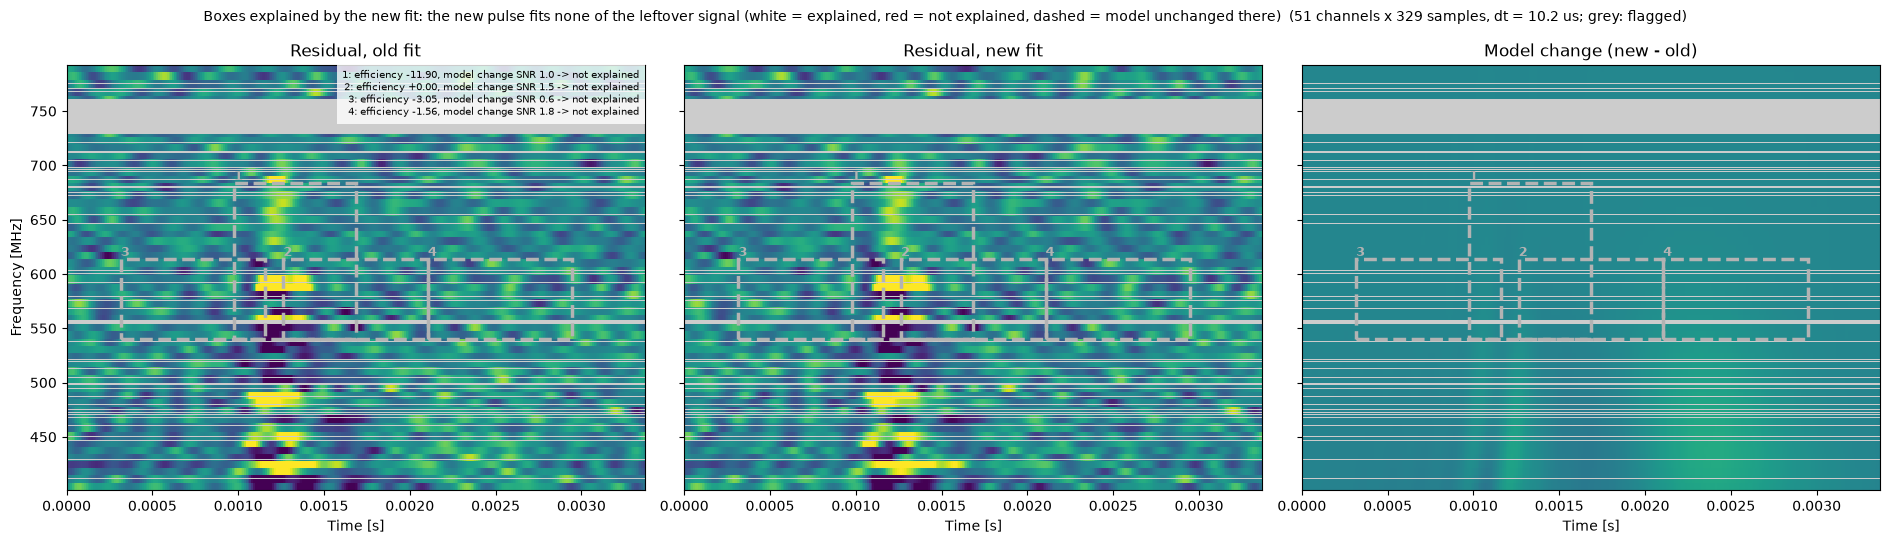

1 -> 2 pulses: delta ELPD = 43.9 (need 32.0), explains leftover signal: False -> reject
final: 1 pulses


In [13]:
import numpy as np
from run import set_priors, run_fit
from likelihood import FD_gaussianlikelihood
from postprocess import (pointwise_log_lik, combine_chains, _loo_by_observation,
                         excess_power_search, boxes_explained, min_box_channels)
from plotting import model_from_draw, plot_boxes_explained

constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=make_orthogonal_poly_log_sed(*burst.spectral_basis),
    fourier_freqs=burst.fourier_freqs,
)

S_MIN = 8.0             # detection SNR: a box must hold this much unexplained signal, a new pulse must change
                        # the model by this much inside it, and delta ELPD must reach S_MIN^2 / 2
N_WARM = 32             # chains (of 64) started from the previous fit plus one new pulse; the rest from scratch
WARM_START_TAU = False  # True: warm chains inherit the previous fit's tau_ref; False: it starts afresh
ROBUST_SCALE = None     # residual search uses sigma_noise_fd as it is, like the fit ("global" re-estimates it)

# narrowest band one pulse can occupy under the spectral prior: the fewest channels a box may span
N_MIN_CH = min_box_channels(burst, set_priors(burst, single_pulse_fn, 1, s_opt=100.0, verbose=False))
print("minimum box width:", N_MIN_CH, "channels;  delta ELPD threshold:", S_MIN ** 2 / 2)

def fit(n, ep=None, prev=None):
    priors = set_priors(burst, single_pulse_fn, n, s_opt=100.0)
    warm = {} if ep is None else dict(warm_start=dict(params=prev["map"], result=ep, M_FD=prev["M"]),
                                      n_warm_chains=N_WARM, warm_start_tau=WARM_START_TAU)
    mcmc = run_fit(burst, single_pulse_fn, priors, FD_gaussianlikelihood, n_pulses=n,
                   num_chains=64, seed=2, repulsion={}, **warm)
    s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()}
    U = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["potential_energy"])
    ll = pointwise_log_lik(burst, single_pulse_fn, s, thin=1)
    post, info = combine_chains(s, ll, U)
    ll_post = ll[info["chain"], info["draw"]]
    best = int(np.argmax(-U[info["chain"], info["draw"]]))          # maximum a posteriori draw
    M, _ = model_from_draw(single_pulse_fn, post, best)
    return dict(mcmc=mcmc, post=post, info=info, M=np.asarray(M),
                map={k: np.asarray(v)[best] for k, v in post.items()},
                elpd=_loo_by_observation(ll_post)[0].sum())

fits, n_final = {1: fit(1)}, 1
for n in range(2, 6):
    ep = excess_power_search(burst, fits[n - 1]["M"], min_snr=S_MIN, min_channels=N_MIN_CH,
                             robust_scale=ROBUST_SCALE)
    if not ep["add_pulse"]:
        break
    fits[n] = fit(n, ep, fits[n - 1])
    check = boxes_explained(burst, fits[n - 1]["M"], fits[n]["M"], ep, min_change_snr=S_MIN)
    plot_boxes_explained(burst, fits[n - 1]["M"], fits[n]["M"], check)
    d_elpd = fits[n]["elpd"] - fits[n - 1]["elpd"]
    accept = check["any_removed"] and d_elpd >= S_MIN ** 2 / 2
    print(f"{n - 1} -> {n} pulses: delta ELPD = {d_elpd:.1f} (need {S_MIN ** 2 / 2:.1f}), "
          f"explains leftover signal: {check['any_removed']} -> {'accept' if accept else 'reject'}")
    if not accept:
        break
    n_final = n
print(f"final: {n_final} pulses")

t [ms] [3.564 4.121 5.427 5.629]   A_snr [43.7 12.7 46.9 35.9]
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


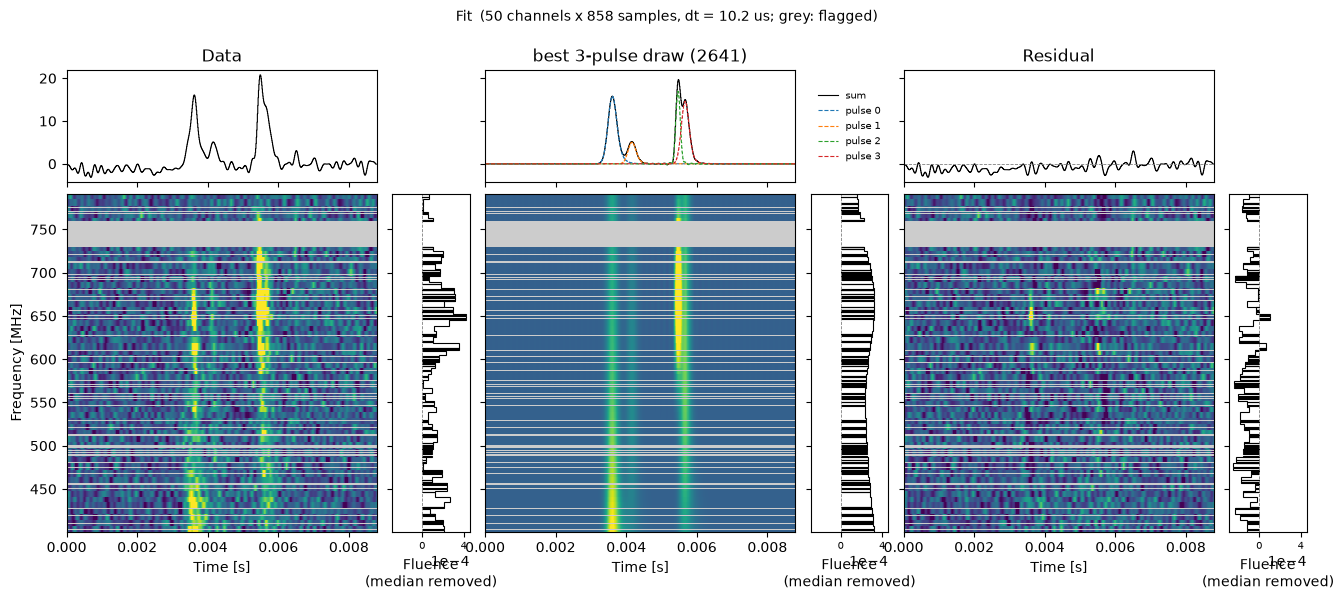

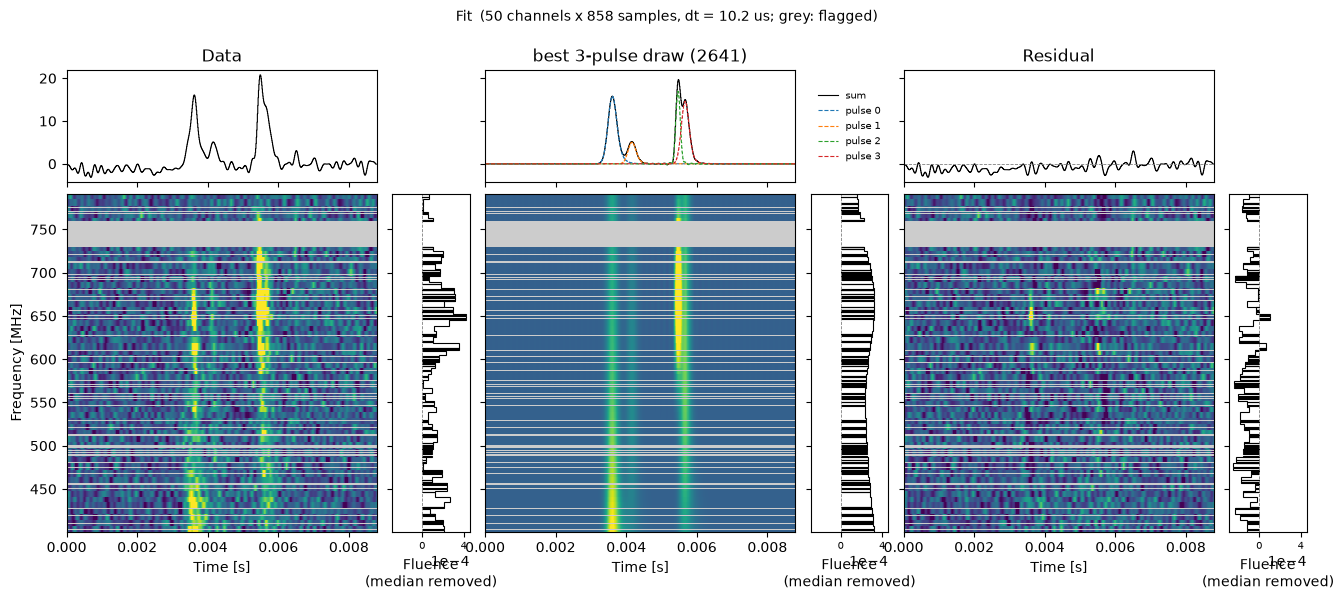

In [4]:
import numpy as np
from postprocess import pointwise_log_lik
from plotting import model_from_draw, plot_fit_TD

post = fits[4]["post"]
ll = pointwise_log_lik(burst, single_pulse_fn, {k: np.asarray(v)[None] for k, v in post.items()}, thin=1)[0].sum(-1)
d = int(np.argmax(ll))
M, Mp = model_from_draw(single_pulse_fn, post, d)
print(f"t [ms] {np.round(post['mean_arrival_time'][d] * 1e3, 3)}   A_snr {np.round(post['A_snr'][d], 1)}")
plot_fit_TD(burst, M, Mp, title_model=f"best 3-pulse draw ({d})")

In [5]:
m = fits[4]["mcmc"]
lp = -np.asarray(m.get_extra_fields(group_by_chain=True)["potential_energy"])   # log posterior, (chains, draws)
s = m.get_samples(group_by_chain=True)
t, a = np.asarray(s["mean_arrival_time"]), np.asarray(s["A_snr"])

print("chain  start   peak lp  median lp   start toas (ms)        median toas (ms)       median A_snr")
for c in np.argsort(-lp.max(axis=1)):
    tm, am = np.median(t[c], axis=0), np.median(a[c], axis=0)
    o = np.argsort(tm)
    print(f"{c:5d}  {'warm' if c < N_WARM else 'random':6s} {lp[c].max():8.1f} {np.median(lp[c]):9.1f}   "
          f"{str(np.round(m.init_times[c] * 1e3, 2)):22s} {str(np.round(tm[o] * 1e3, 2)):22s} {np.round(am[o], 1)}")

chain  start   peak lp  median lp   start toas (ms)        median toas (ms)       median A_snr
   26  warm    -3477.8   -3485.1   [3.57 5.42 5.62 4.64]  [3.57 4.12 5.43 5.63]  [43.  13.7 47.4 35.9]
   30  warm    -3477.9   -3485.6   [3.57 5.42 5.62 2.03]  [3.57 4.12 5.43 5.63]  [43.  13.8 47.4 35.8]
   15  warm    -3478.2   -3485.0   [3.57 5.42 5.62 4.28]  [3.57 4.12 5.43 5.63]  [42.9 13.7 47.3 35.8]
    9  warm    -3478.5   -3485.3   [3.57 5.42 5.62 4.44]  [3.57 4.12 5.43 5.63]  [43.  13.5 47.3 35.8]
   24  warm    -3478.6   -3485.1   [3.57 5.42 5.62 4.23]  [3.57 4.12 5.43 5.63]  [43.  13.6 47.5 35.8]
    2  warm    -3478.6   -3485.3   [3.57 5.42 5.62 4.24]  [3.57 4.12 5.43 5.63]  [43.  13.7 47.5 35.7]
   23  warm    -3478.7   -3484.9   [3.57 5.42 5.62 2.86]  [3.57 4.12 5.43 5.63]  [43.1 13.6 47.3 35.9]
    4  warm    -3478.8   -3485.6   [3.57 5.42 5.62 4.22]  [3.57 4.13 5.43 5.63]  [43.  13.7 47.3 35.9]
    1  warm    -3479.0   -3485.5   [3.57 5.42 5.62 1.98]  [3.57 4.12 5.43 5.63]  

rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


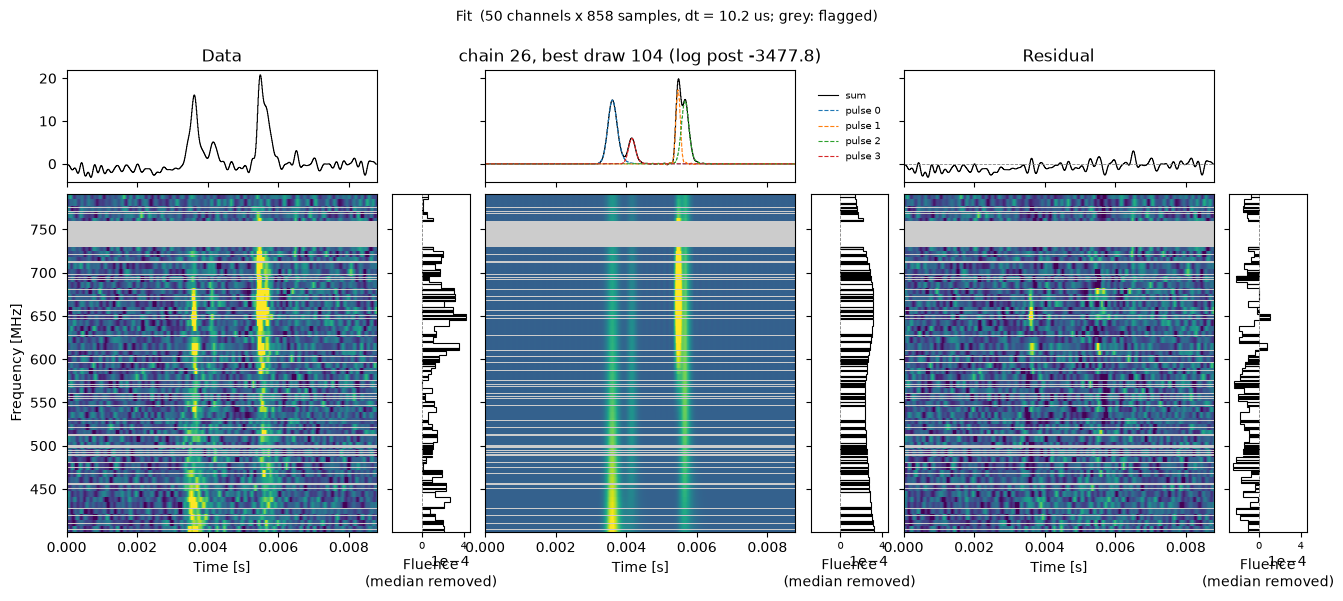

box 5.22-6.31 ms, 404-788 MHz (SNR 27.2): model change SNR 23.7, efficiency +0.72 -> explained
box 3.46-3.80 ms, 579-686 MHz (SNR 15.1): model change SNR 2.7, efficiency +1.17 -> untouched (model change SNR < 5)
box 3.71-4.26 ms, 404-788 MHz (SNR 14.5): model change SNR 13.3, efficiency +0.70 -> explained
box 0.00-3.29 ms + 7.69-8.79 ms (wraps), 535-788 MHz (SNR 12.9): model change SNR 3.2, efficiency +3.78 -> untouched (model change SNR < 5)
  -> the new pulse fits leftover signal
rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


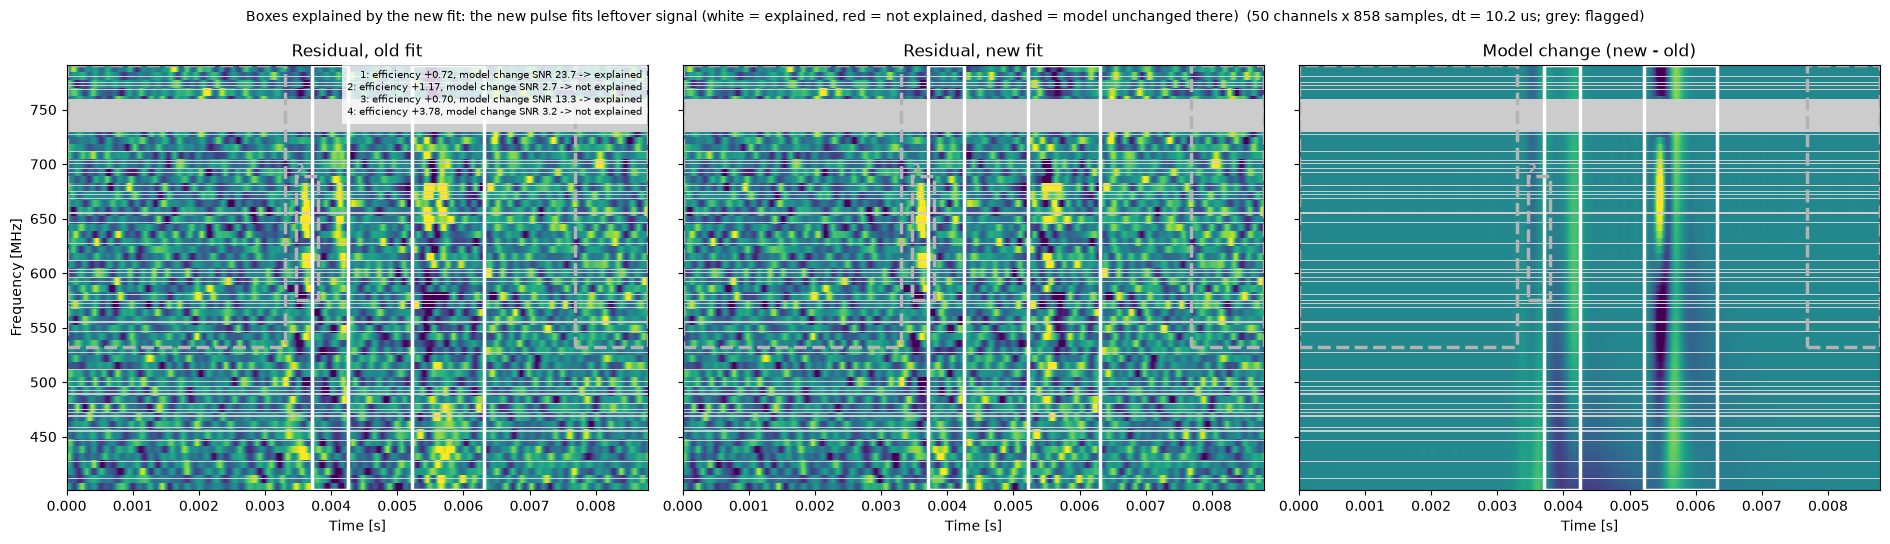

In [8]:
from plotting import plot_fit_TD

chains = [26]                      # chains to plot
m = fits[4]["mcmc"]
s = {k: np.asarray(v) for k, v in m.get_samples(group_by_chain=True).items()}
lp = -np.asarray(m.get_extra_fields(group_by_chain=True)["potential_energy"])
ep2 = excess_power_search(burst, fits[2]["M"], verbose=False)     # the 2-pulse residual boxes

for c in chains:
    d = int(np.argmax(lp[c]))                                       # this chain's best draw
    M, M_pulses = model_from_draw(single_pulse_fn, {k: v[c] for k, v in s.items()}, d)
    plot_fit_TD(burst, M, M_pulses, title_model=f"chain {c}, best draw {d} (log post {lp[c, d]:.1f})")
    check = boxes_explained(burst, fits[2]["M"], np.asarray(M), ep2)
    plot_boxes_explained(burst, fits[2]["M"], np.asarray(M), check)

rebaseline: subtracting each channel's median over time. The DC (zero-frequency) bin is purposely removed from the data, so every channel's time series has zero mean and bright channels sit below zero off-pulse. This restores the off-pulse level for display only; the fit is unaffected.


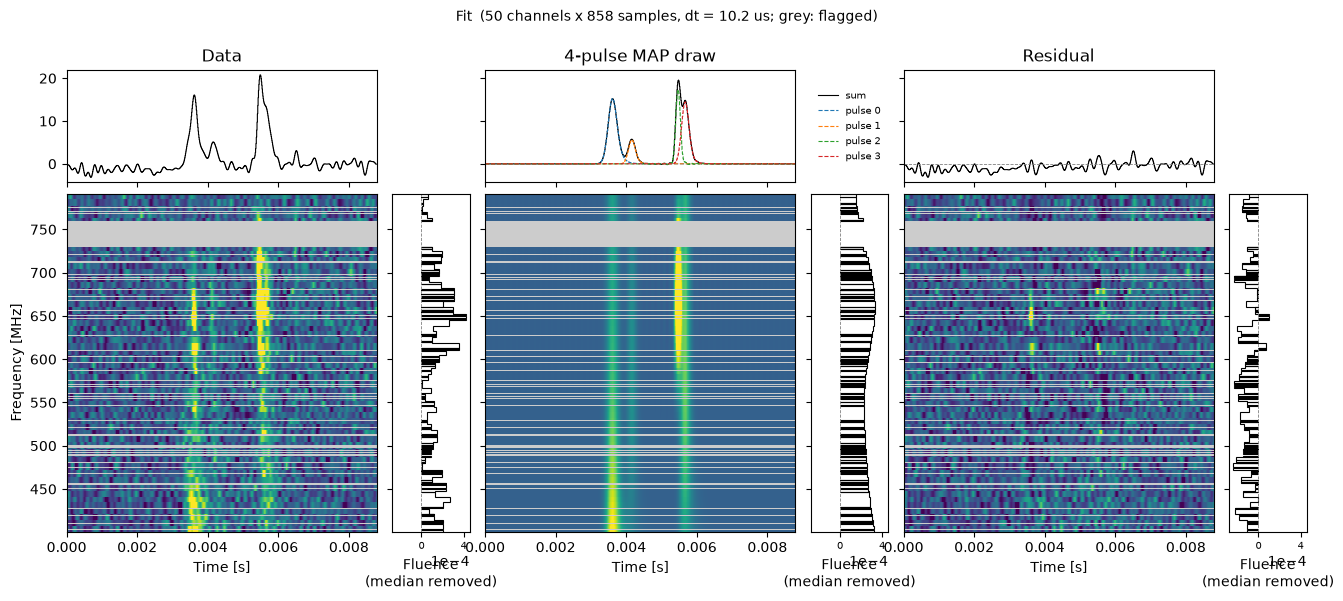

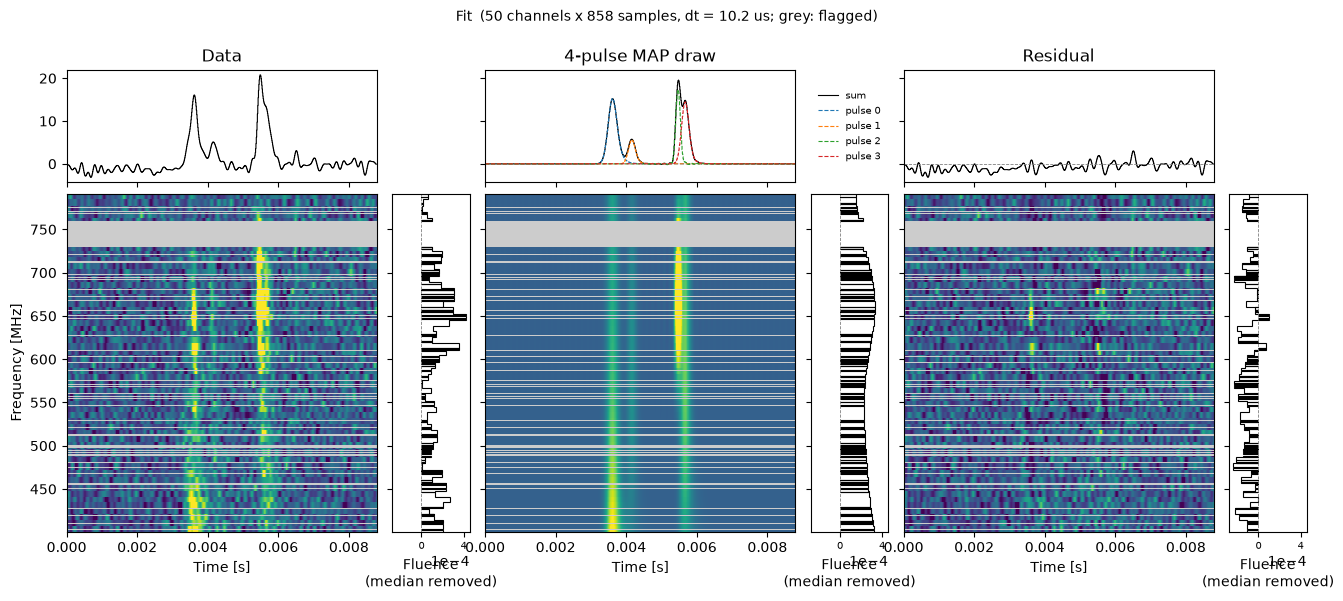

In [7]:
from plotting import plot_fit_TD

pulse_n = 4
p = fits[pulse_n]["map"]
M, M_pulses = model_from_draw(single_pulse_fn, {k: np.asarray(v)[None] for k, v in p.items()}, 0)
plot_fit_TD(burst, M, M_pulses, title_model=str(pulse_n)+"-pulse MAP draw")

In [15]:
m3 = fits[3]["mcmc"]
s3 = {k: np.asarray(v) for k, v in m3.get_samples(group_by_chain=True).items()}
lp3 = -np.asarray(m3.get_extra_fields(group_by_chain=True)["potential_energy"])
tau3 = s3["tau_ref_shared"] if "tau_ref_shared" in s3 else s3["tau_ref"][..., 0]

print("chain  peak lp   median toas (ms)        median tau_ref (us)")
for c in np.argsort(-lp3.max(axis=1)):
    tm = np.sort(np.median(s3["mean_arrival_time"][c], axis=0))
    print(f"{c:5d} {lp3[c].max():8.1f}   {str(np.round(tm * 1e3, 2)):22s} {np.median(tau3[c]) * 1e6:7.1f}")

chain  peak lp   median toas (ms)        median tau_ref (us)
   49  -3559.7   [3.57 5.42 5.63]          51.7
   47  -3726.8   [3.52 4.09 5.46]         124.6
   34  -3744.5   [3.48 5.41 6.43]         250.0
   35  -3744.7   [3.48 5.41 7.65]         246.8
   33  -3745.0   [3.48 5.41 7.35]         244.4
   17  -3745.1   [3.49 5.41 7.  ]         241.0
   23  -3745.1   [3.48 5.41 7.61]         245.5
   61  -3745.2   [3.49 5.41 6.43]         248.4
   51  -3745.2   [3.48 5.41 7.65]         248.4
   46  -3745.2   [3.49 5.41 6.43]         246.8
   31  -3745.2   [3.48 5.41 7.52]         241.9
   12  -3745.2   [3.48 5.41 7.63]         248.5
   29  -3745.3   [3.48 5.41 7.63]         246.0
   16  -3745.4   [3.48 5.41 6.43]         250.8
    9  -3745.5   [3.48 5.41 7.66]         249.0
   21  -3745.5   [3.48 5.41 7.66]         246.3
    2  -3745.6   [3.48 5.41 7.57]         250.1
   13  -3745.6   [3.48 5.41 7.57]         248.2
   63  -3745.6   [3.49 5.41 6.43]         247.5
   26  -3745.6   [3.48 5.41

In [10]:
m = fits[4]["mcmc"]
lp = -np.asarray(m.get_extra_fields(group_by_chain=True)["potential_energy"])
s = m.get_samples(group_by_chain=True)
t, a, sg = (np.asarray(s[k]) for k in ("mean_arrival_time", "A_snr", "sigma"))

print("chain  peak lp   5.5 ms pair: toas (ms)   A_snr          sigma (ms)")
for c in np.argsort(-lp.max(axis=1)):
    d = int(np.argmax(lp[c]))
    pair = np.flatnonzero((t[c, d] > 5.2e-3) & (t[c, d] < 5.9e-3))
    if len(pair) == 2:
        o = pair[np.argsort(t[c, d, pair])]
        print(f"{c:5d} {lp[c, d]:8.1f}   {str(np.round(t[c, d, o] * 1e3, 2)):18s} "
              f"{str(np.round(a[c, d, o], 1)):14s} {np.round(sg[c, d, o] * 1e3, 3)}")

chain  peak lp   5.5 ms pair: toas (ms)   A_snr          sigma (ms)
   26  -3477.8   [5.43 5.63]        [47.5 35.4]    [0.056 0.097]
   30  -3477.9   [5.43 5.63]        [46.8 36.5]    [0.055 0.097]
   15  -3478.2   [5.43 5.62]        [47.4 35.7]    [0.056 0.095]
    9  -3478.5   [5.43 5.63]        [47.8 35.8]    [0.055 0.102]
   24  -3478.6   [5.43 5.63]        [48.  35.5]    [0.053 0.096]
    2  -3478.6   [5.43 5.63]        [46.4 35.2]    [0.058 0.096]
   23  -3478.7   [5.43 5.63]        [48.5 35.9]    [0.057 0.096]
    4  -3478.8   [5.43 5.63]        [47.4 35.2]    [0.056 0.09 ]
    1  -3479.0   [5.43 5.63]        [47.7 36.6]    [0.055 0.094]
   27  -3479.2   [5.43 5.63]        [48.1 35.2]    [0.056 0.094]
   16  -3479.3   [5.42 5.62]        [48.  36.8]    [0.054 0.094]
    6  -3479.3   [5.43 5.63]        [47.3 35.8]    [0.055 0.092]
    5  -3479.7   [5.43 5.63]        [47.1 35.9]    [0.057 0.098]
   60  -3479.7   [5.43 5.62]        [46.  35.2]    [0.056 0.098]
   18  -3479.7   [5.43

# Computational diagnostics

In [ ]:
print("peak Memory usage in GB",jax.devices()[0].memory_stats()["peak_bytes_in_use"] / 1e9)